## Preliminaries

In [1]:
import pandas as pd
from src.extract import fetch_full_dataset
from src.preprocessing_functions import *

In [2]:
df = fetch_full_dataset()
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1771 entries, 2020-01-01 to 2026-10-14
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   real_yield_10y           1695 non-null   float64
 1   breakeven_inflation_10y  1696 non-null   float64
 2   dxy_broad_goods          1694 non-null   float64
 3   treasury_10y_nominal     1695 non-null   float64
 4   vix_index                1736 non-null   float64
 5   gold_price_usd           1708 non-null   float64
dtypes: float64(6)
memory usage: 96.9 KB


In [3]:
show_missings(df)

dxy_broad_goods            0.043478
real_yield_10y             0.042914
treasury_10y_nominal       0.042914
breakeven_inflation_10y    0.042349
gold_price_usd             0.035573
vix_index                  0.019763
dtype: float64

In [4]:
show_missings(df.ffill())

real_yield_10y             0.000565
breakeven_inflation_10y    0.000565
dxy_broad_goods            0.000565
treasury_10y_nominal       0.000565
vix_index                  0.000565
gold_price_usd             0.000565
dtype: float64

In [5]:
df = df.ffill().dropna()

In [6]:
df.describe()

,real_yield_10y,breakeven_inflation_10y,dxy_broad_goods,treasury_10y_nominal,vix_index,gold_price_usd
count,1770.000000,1770.000000,1770.000000,1770.000000,1770.000000,1770.000000
mean,0.914401,2.223322,119.550681,3.137723,20.609452,2472.116836
std,1.271998,0.352531,4.169052,1.415147,7.525981,973.388947
min,-1.190000,0.500000,110.504600,0.520000,11.860000,1477.300049
25%,-0.567500,2.220000,116.584775,1.610000,15.840000,1810.749969
50%,1.570000,2.310000,120.081950,3.820000,18.625000,1962.199951
75%,1.960000,2.380000,122.091175,4.280000,23.495000,2842.125000
max,2.950000,3.020000,130.041300,5.310000,82.690000,5318.399902


In [7]:
show_asymmetry(df)

vix_index                  2.745618
gold_price_usd             1.302578
dxy_broad_goods           -0.089619
real_yield_10y            -0.454435
treasury_10y_nominal      -0.574273
breakeven_inflation_10y   -1.751558


Cont


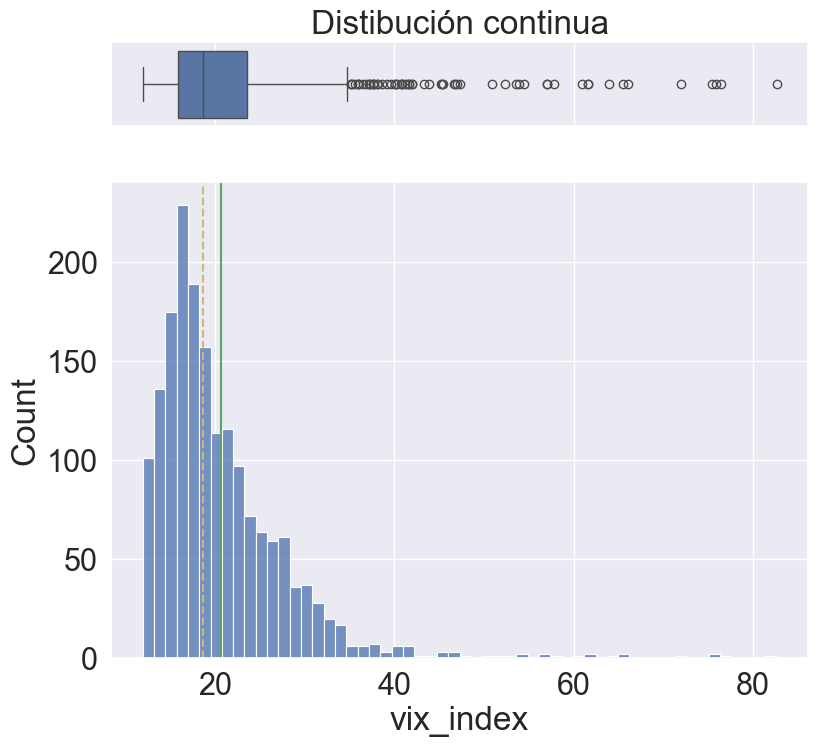

In [8]:
col = 'vix_index'
plot_col(df[col])

## Feature Engineering

In [9]:
# Se aplica retardo de 1 dia sobre variables macro para evitar Lookahead Bias (horario de publicación luego del cierre)
macro_cols = [
    "real_yield_10y",
    "breakeven_inflation_10y",
    "dxy_broad_goods",
    "treasury_10y_nominal",
    "vix_index",
]
df = calculate_lag(df,macro_cols)

In [10]:
show_missings(df)

real_yield_10y_Lag1             0.000565
breakeven_inflation_10y_Lag1    0.000565
dxy_broad_goods_Lag1            0.000565
treasury_10y_nominal_Lag1       0.000565
vix_index_Lag1                  0.000565
dtype: float64